[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ahmedelshazly27/mizan-kuwait-energy-toolkit/blob/main/notebooks/06-storage-and-controls.ipynb)

In [1]:
# On Colab: clone the repository and install it (inputs are committed, no credentials needed).
import os, sys
if "google.colab" in sys.modules and not os.path.exists("mizan-kuwait-energy-toolkit"):
    !git clone --depth 1 https://github.com/ahmedelshazly27/mizan-kuwait-energy-toolkit.git
    %pip install -q -e "mizan-kuwait-energy-toolkit[pv,econ,system]" matplotlib
    os.chdir("mizan-kuwait-energy-toolkit")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from kwtk import viz; viz.style()

# 6. Storage, controls and curtailment

Three designs with the same PV: no storage; a battery behind a 900 MW connection
storing what the limit would curtail; a battery behind a 1,350 MW connection shaving
the system's net peak.

In [2]:
from kwtk.plant.evaluate import evaluate
from kwtk.plant import report
ids = ['shagaya-scale-pv-tracker', 'shagaya-scale-pv-storage-export-limit', 'shagaya-scale-pv-storage-peak-shaving']
runs = {k: evaluate(f'configs/examples/{k}.yaml') for k in ids}
report.compare([r['result'] for r in runs.values()]).round(2)

,shagaya-scale-pv-tracker,shagaya-scale-pv-storage-export-limit,shagaya-scale-pv-storage-peak-shaving
"Export, MWh/yr (mean)",3132101.70,3093213.80,3114957.82
"Specific yield, kWh/kWp",2191.86,2164.62,2179.84
AC capacity factor,0.30,0.30,0.30
"Inverter clipping, MWh/yr",3956.38,3956.38,3956.38
"Curtailed at POI, MWh/yr",0.00,6957.62,0.00
"Battery discharge, MWh/yr",0.00,110255.54,30286.10
"Mean soiling loss, %",2.99,2.99,2.99
Cleanings per year,21.67,21.67,21.67
"Capex, million USD",1677.19,2001.49,2001.49
"LCOE real, fils/kWh",17.24,21.31,21.19


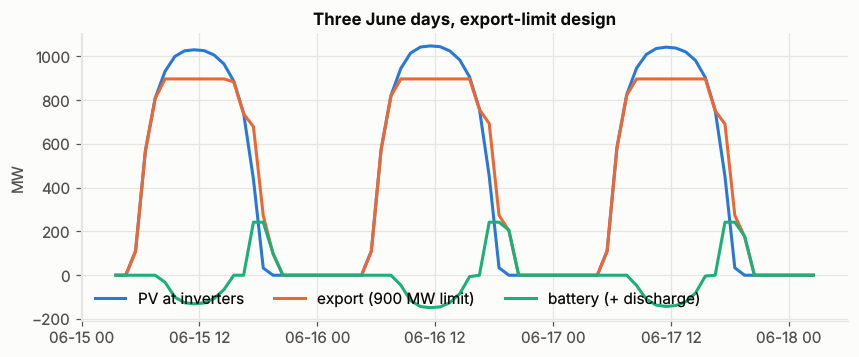

In [3]:
h = runs['shagaya-scale-pv-storage-export-limit']['hourly']
d = h['2023-06-15':'2023-06-17']; t = d.index.tz_convert('Asia/Kuwait')
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(t, d.pv_ac, label='PV at inverters'); ax.plot(t, d.export, label='export (900 MW limit)'); ax.plot(t, d.battery, label='battery (+ discharge)')
ax.set_title('Three June days, export-limit design'); ax.set_ylabel('MW'); ax.legend(ncol=3, loc='lower left'); plt.show()